In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split #machine learning
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression #for logistic regression
from sklearn.ensemble import RandomForestClassifier # random forest
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE #handle imbalance

import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")

In [2]:
df=pd.read_csv(r"E:\downloads\PS_20174392719_1491204439457_log.csv")

In [3]:
print("shape of the data (rows,columns): ")
print (df.shape)

shape of the data (rows,columns): 
(6362620, 11)


In [4]:
print("Columns names: ")
print(df.columns.tolist())

Columns names: 
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [5]:
print(df.head(10))

   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815      170136.00       160296.36   
1     1   PAYMENT   1864.28  C1666544295       21249.00        19384.72   
2     1  TRANSFER    181.00  C1305486145         181.00            0.00   
3     1  CASH_OUT    181.00   C840083671         181.00            0.00   
4     1   PAYMENT  11668.14  C2048537720       41554.00        29885.86   
5     1   PAYMENT   7817.71    C90045638       53860.00        46042.29   
6     1   PAYMENT   7107.77   C154988899      183195.00       176087.23   
7     1   PAYMENT   7861.64  C1912850431      176087.23       168225.59   
8     1   PAYMENT   4024.36  C1265012928        2671.00            0.00   
9     1     DEBIT   5337.77   C712410124       41720.00        36382.23   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0            0.00        0               0  
1  M2044282225            

In [6]:
print("Data Types: ")
print(df.dtypes)

Data Types: 
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object


In [7]:
print(" Detailed Information: ")
print(df.info())

 Detailed Information: 
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB
None


In [8]:
print(" Missing Values in each column: ")
print(df.isnull().sum())

 Missing Values in each column: 
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [9]:
print("Number of exact duplicate rows: ")
print(df.duplicated().sum())

Number of exact duplicate rows: 
0


In [10]:
print("Unique Values: ")
print(df.nunique())

Unique Values: 
step                  743
type                    5
amount            5316900
nameOrig          6353307
oldbalanceOrg     1845844
newbalanceOrig    2682586
nameDest          2722362
oldbalanceDest    3614697
newbalanceDest    3555499
isFraud                 2
isFlaggedFraud          2
dtype: int64


In [11]:
print(df.describe())

               step        amount  oldbalanceOrg  newbalanceOrig  \
count  6.362620e+06  6.362620e+06   6.362620e+06    6.362620e+06   
mean   2.433972e+02  1.798619e+05   8.338831e+05    8.551137e+05   
std    1.423320e+02  6.038582e+05   2.888243e+06    2.924049e+06   
min    1.000000e+00  0.000000e+00   0.000000e+00    0.000000e+00   
25%    1.560000e+02  1.338957e+04   0.000000e+00    0.000000e+00   
50%    2.390000e+02  7.487194e+04   1.420800e+04    0.000000e+00   
75%    3.350000e+02  2.087215e+05   1.073152e+05    1.442584e+05   
max    7.430000e+02  9.244552e+07   5.958504e+07    4.958504e+07   

       oldbalanceDest  newbalanceDest       isFraud  isFlaggedFraud  
count    6.362620e+06    6.362620e+06  6.362620e+06    6.362620e+06  
mean     1.100702e+06    1.224996e+06  1.290820e-03    2.514687e-06  
std      3.399180e+06    3.674129e+06  3.590480e-02    1.585775e-03  
min      0.000000e+00    0.000000e+00  0.000000e+00    0.000000e+00  
25%      0.000000e+00    0.000000e+00

In [12]:
# fraud vs legitimate

print("Fraud vs Legitimate Transactions:")
print(df['isFraud'].value_counts())

print("\nFraud Percentage:")
fraud_percentage = (df['isFraud'].sum() / len(df)) * 100
print(f"{fraud_percentage:.4f}%")

Fraud vs Legitimate Transactions:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud Percentage:
0.1291%


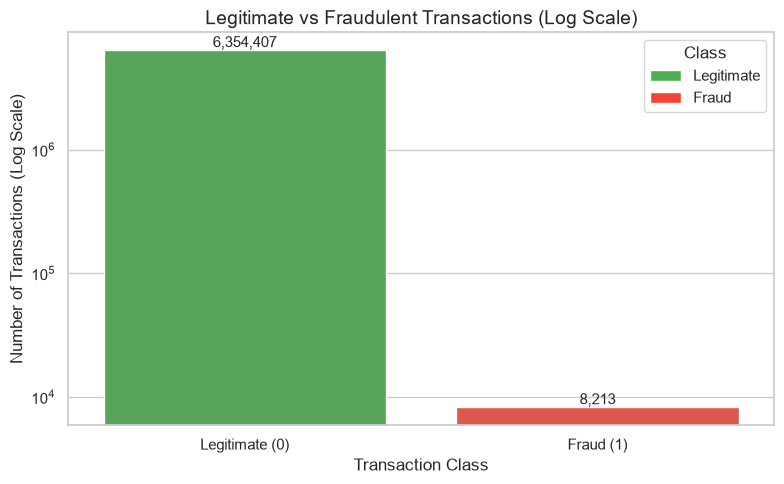

In [14]:
#visualizing
plt.figure(figsize=(8, 5))

ax = sns.countplot(x='isFraud', data=df, palette=['#4CAF50', '#F44336'])  # Green for Legitimate, Red for Fraud

# log scale so the small fraud bar becomes visible
plt.yscale('log')

plt.title("Legitimate vs Fraudulent Transactions (Log Scale)", fontsize=14)
plt.xlabel("Transaction Class", fontsize=12)
plt.ylabel("Number of Transactions (Log Scale)", fontsize=12)
plt.xticks([0, 1], ['Legitimate (0)', 'Fraud (1)'])

# Add the actual numbers on top of the bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height):,}', 
                (p.get_x() + p.get_width() / 2., height), 
                ha='center', va='bottom', fontsize=11)

# Add legend manually
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4CAF50', label='Legitimate'),
    Patch(facecolor='#F44336', label='Fraud')
]
plt.legend(handles=legend_elements, title="Class")

plt.tight_layout()
plt.show()


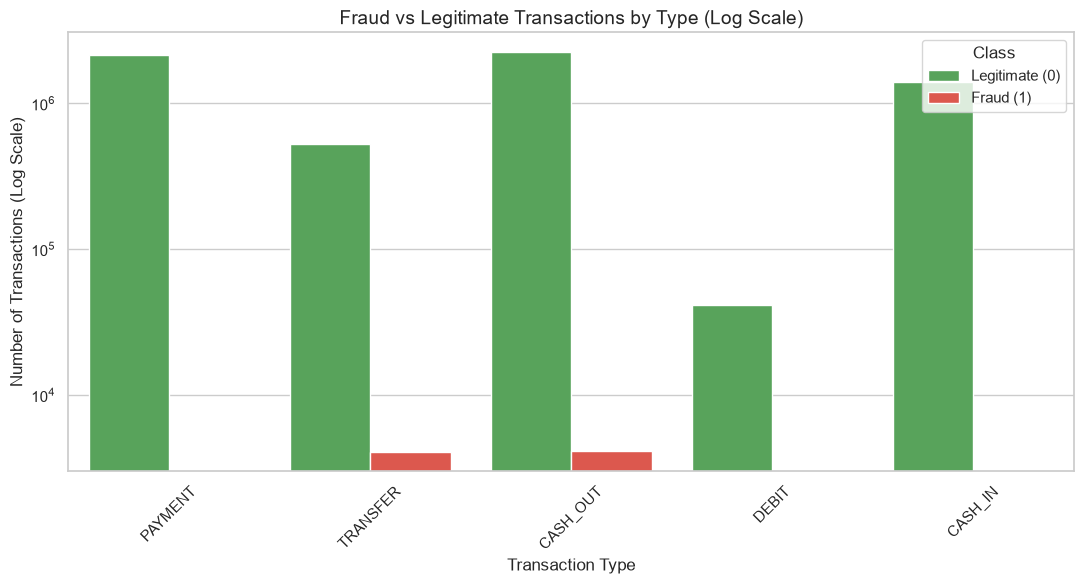

In [16]:
# fraud by transaction type
plt.figure(figsize=(11, 6))

ax = sns.countplot(
    data=df, 
    x='type', 
    hue='isFraud', 
    palette=['#4CAF50', '#F44336']  # Green = Legitimate, Red = Fraud
)

# log scale so fraud bars can be seen
plt.yscale('log')

plt.title("Fraud vs Legitimate Transactions by Type (Log Scale)", fontsize=14)
plt.xlabel("Transaction Type", fontsize=12)
plt.ylabel("Number of Transactions (Log Scale)", fontsize=12)
plt.xticks(rotation=45)

#legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Legitimate (0)', 'Fraud (1)'], title='Class')

plt.tight_layout()
plt.show()

Number of Fraud Cases by Type:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


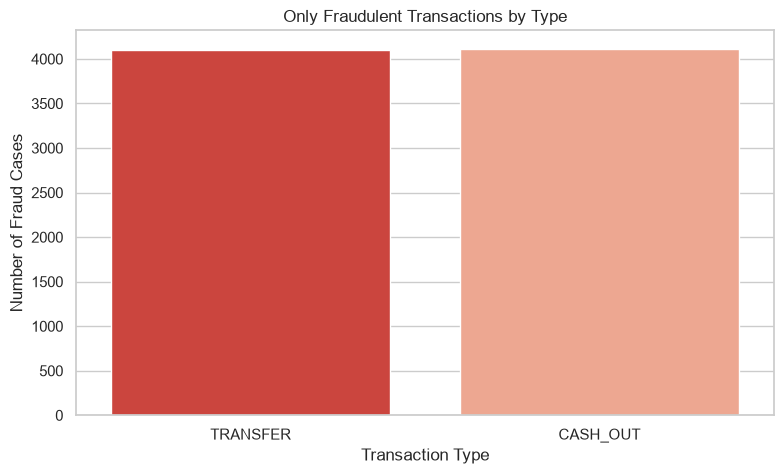

In [17]:
#only fraud cases by type
fraud_df = df[df['isFraud'] == 1]

print("Number of Fraud Cases by Type:")
print(fraud_df['type'].value_counts())

plt.figure(figsize=(9,5))
sns.countplot(data=fraud_df, x='type', palette='Reds_r')
plt.title("Only Fraudulent Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraud Cases")
plt.show()

Average Transaction Amount:
isFraud
0    1.781970e+05
1    1.467967e+06
Name: amount, dtype: float64


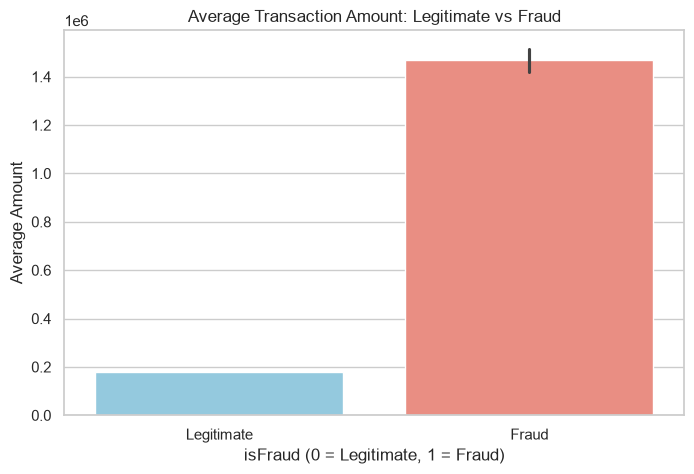

In [19]:
#Average, Fraud vs Legitimate- transaction amount
print("Average Transaction Amount:")
print(df.groupby('isFraud')['amount'].mean())

plt.figure(figsize=(8,5))
sns.barplot(x='isFraud', y='amount', data=df, palette=['skyblue', 'salmon'])
plt.title("Average Transaction Amount: Legitimate vs Fraud")
plt.xlabel("isFraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Average Amount")
plt.xticks([0,1], ['Legitimate', 'Fraud'])
plt.show()

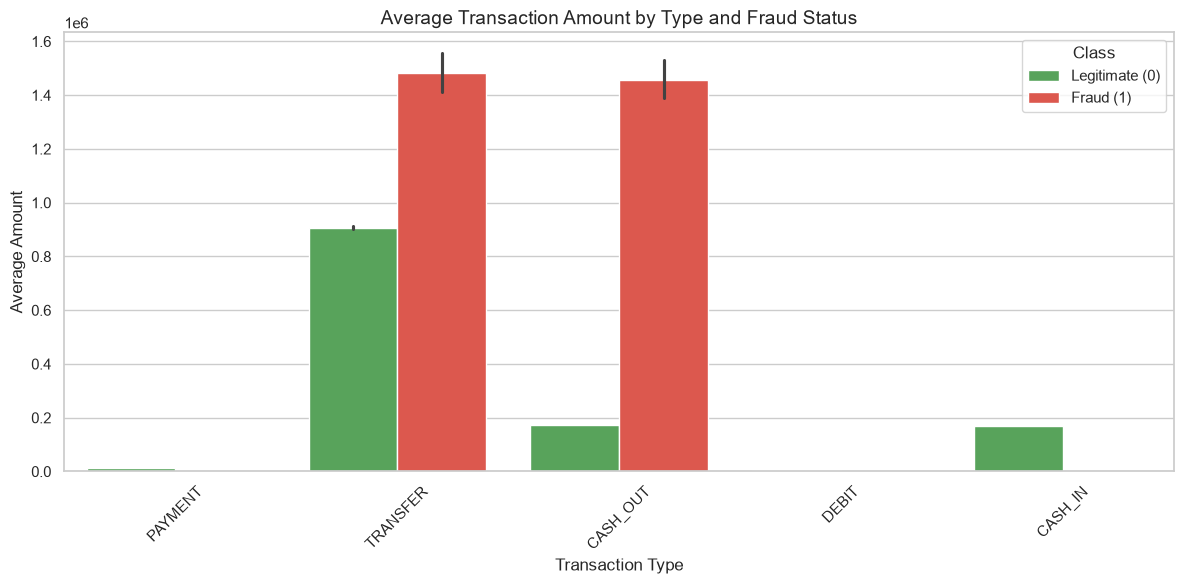

In [21]:
#transaction amount -type of transaction and how it relates to fraud
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=df, 
    x='type', 
    y='amount', 
    hue='isFraud', 
    palette=['#4CAF50', '#F44336']  # Green = Legitimate, Red = Fraud
)

plt.title("Average Transaction Amount by Type and Fraud Status", fontsize=14)
plt.xlabel("Transaction Type", fontsize=12)
plt.ylabel("Average Amount", fontsize=12)
plt.xticks(rotation=45)

# Fix the legend properly
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ['Legitimate (0)', 'Fraud (1)'], title='Class')

plt.tight_layout()
plt.show()

In [22]:
summary = df.groupby(['type', 'isFraud'])['amount'].mean().unstack()
summary.columns = ['Legitimate', 'Fraud']
summary = summary.round(2)

print(summary)

          Legitimate       Fraud
type                            
CASH_IN    168920.24         NaN
CASH_OUT   173917.16  1455102.59
DEBIT        5483.67         NaN
PAYMENT     13057.60         NaN
TRANSFER   906229.01  1480891.67


In [23]:
print("="*50)
print("KEY EDA INSIGHTS")
print("="*50)
print("1. Total transactions: {:,}".format(len(df)))
print("2. Total fraud cases: {:,}".format(df['isFraud'].sum()))
print("3. Fraud rate: {:.4f}%".format((df['isFraud'].sum()/len(df))*100))
print("4. Almost all fraud happens in TRANSFER and CASH_OUT")
print("5. Fraudulent transactions tend to have higher average amounts")
print("="*50)

KEY EDA INSIGHTS
1. Total transactions: 6,362,620
2. Total fraud cases: 8,213
3. Fraud rate: 0.1291%
4. Almost all fraud happens in TRANSFER and CASH_OUT
5. Fraudulent transactions tend to have higher average amounts


In [24]:
#selected columns for modelling 

df_model = df[['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 
               'oldbalanceDest', 'newbalanceDest', 'isFraud']].copy()

# Encode the 'type' column
le = LabelEncoder()
df_model['type'] = le.fit_transform(df_model['type'])

# Features and target
X = df_model.drop('isFraud', axis=1)
y = df_model['isFraud']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (4453834, 6)
Testing set shape: (1908786, 6)


In [25]:
#solving the imbalance in the data
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("After SMOTE - Fraud counts:\n", pd.Series(y_train_res).value_counts())

After SMOTE - Fraud counts:
 isFraud
0    4448085
1    4448085
Name: count, dtype: int64


In [26]:
#training models
# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_res, y_train_res)

# 2. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_res, y_train_res)

# 3. XGBoost
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train_res, y_train_res)

print("All models trained successfully.")

All models trained successfully.


In [27]:
#checking model accuracy
models = {
    "Logistic Regression": lr,
    "Random Forest": rf,
    "XGBoost": xgb
}

for name, model in models.items():
    print(f"\n===== {name} =====")
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    print(classification_report(y_test, y_pred))
    print("AUC-ROC Score:", round(roc_auc_score(y_test, y_prob), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


===== Logistic Regression =====
              precision    recall  f1-score   support

           0       1.00      0.96      0.98   1906322
           1       0.03      0.87      0.05      2464

    accuracy                           0.96   1908786
   macro avg       0.51      0.91      0.51   1908786
weighted avg       1.00      0.96      0.98   1908786

AUC-ROC Score: 0.9717
Confusion Matrix:
 [[1822766   83556]
 [    316    2148]]

===== Random Forest =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906322
           1       0.63      0.96      0.76      2464

    accuracy                           1.00   1908786
   macro avg       0.82      0.98      0.88   1908786
weighted avg       1.00      1.00      1.00   1908786

AUC-ROC Score: 0.9989
Confusion Matrix:
 [[1904955    1367]
 [    108    2356]]

===== XGBoost =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906

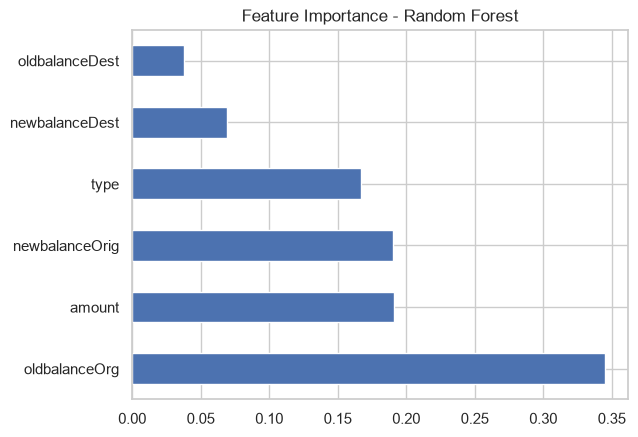

In [28]:
#the feature that helps
feat_importances = pd.Series(rf.feature_importances_, index=X.columns)
feat_importances.nlargest(6).plot(kind='barh')
plt.title("Feature Importance - Random Forest")
plt.show()

In [29]:
#creating files to use for power Bi
#sample transactions of 200,000 rows

df.sample(200000, random_state=42)[['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
                                     'oldbalanceDest', 'newbalanceDest', 'isFraud']].to_csv("transactions_sample.csv", index=False)
print("1. transactions_sample.csv created")


1. transactions_sample.csv created


In [30]:
#fraud by type file

df.groupby(['type', 'isFraud']).size().reset_index(name='count').to_csv("fraud_by_type.csv", index=False)
print("2. fraud_by_type.csv created")

2. fraud_by_type.csv created


In [31]:
#model performance file

model_performance = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Precision': [0.03, 0.63, 0.41],
    'Recall': [0.87, 0.96, 0.99],
    'F1_Score': [0.05, 0.76, 0.58],
    'AUC_ROC': [0.9717, 0.9989, 0.9993]
})

model_performance.to_csv("model_performance.csv", index=False)

print("model_performance.csv created successfully!")
print(model_performance)

model_performance.csv created successfully!
                 Model  Precision  Recall  F1_Score  AUC_ROC
0  Logistic Regression       0.03    0.87      0.05   0.9717
1        Random Forest       0.63    0.96      0.76   0.9989
2              XGBoost       0.41    0.99      0.58   0.9993


In [32]:
#feature importance file

df_model = df[['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
               'oldbalanceDest', 'newbalanceDest', 'isFraud']].copy()

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_model['type'] = le.fit_transform(df_model['type'])

X = df_model.drop('isFraud', axis=1)


pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False).to_csv("feature_importance.csv", index=False)

print("feature_importance.csv created successfully!")

feature_importance.csv created successfully!


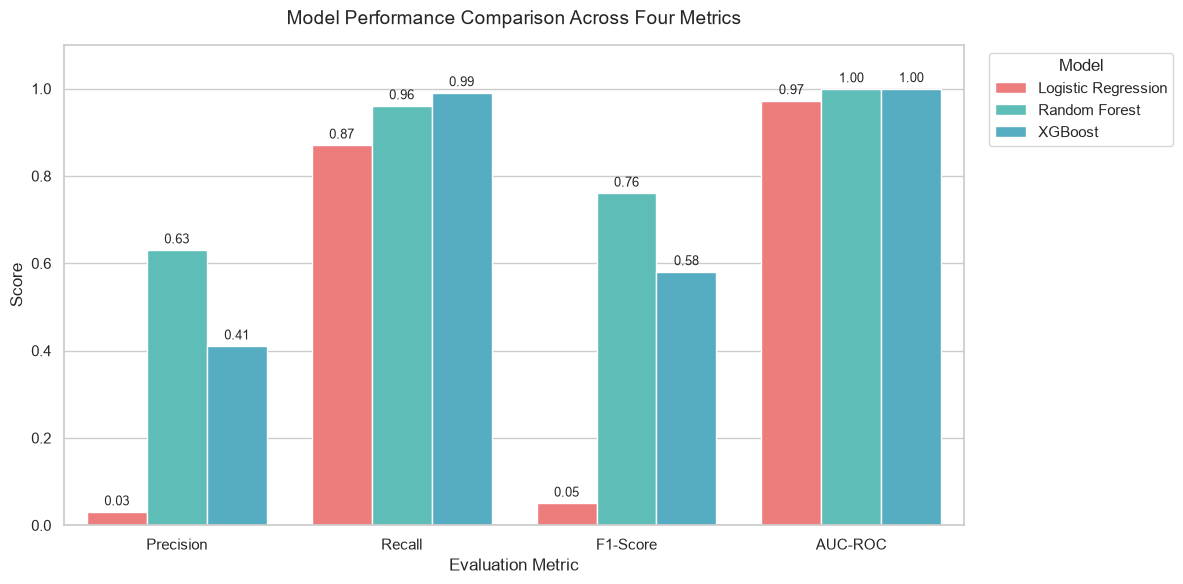

In [35]:
data = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'] * 4,
    'Metric': ['Precision']*3 + ['Recall']*3 + ['F1-Score']*3 + ['AUC-ROC']*3,
    'Score': [
        0.03, 0.63, 0.41,          # Precision
        0.87, 0.96, 0.99,          # Recall
        0.05, 0.76, 0.58,          # F1-Score
        0.9717, 0.9989, 0.9993     # AUC-ROC
    ]
}

df_metrics = pd.DataFrame(data)

# Set style
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")

# Create grouped bar chart
ax = sns.barplot(
    data=df_metrics,
    x='Metric',
    y='Score',
    hue='Model',
    palette=['#FF6B6B', '#4ECDC4', '#45B7D1']  # Nice distinct colours
)

plt.title('Model Performance Comparison Across Four Metrics', fontsize=14, pad=15)
plt.xlabel('Evaluation Metric', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.ylim(0, 1.1)
plt.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')

# Add value labels on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()